# 01. Знакомство с сигналом

Цели: увидеть, где мышечная активность и где покой; есть ли сетевая помеха; что происходит внутри 5-секундной попытки.
Данные: dev-участники (`configs/splits.yaml`), 12 каналов запястья, без какой-либо фильтрации (только то, что сделал усилитель: 10–450 Гц).

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import signal

from data import build_index, load_trial, FS, GESTURE_NAMES, GESTURE_SHORT, REST_GESTURE
import viz
viz.setup()

idx = build_index()
print(len(idx), "trials")
idx.groupby(["participant", "session"]).size().unstack()

1785 trials


session,1,2,3
participant,,,
11,119,119,119
21,119,119,119
24,119,119,119
27,119,119,119
38,119,119,119


## 1. Сырой сигнал

Одна попытка каждого из четырёх классов, 12 каналов запястья друг под другом, **общий масштаб** во всех панелях —
чтобы амплитуды можно было сравнивать напрямую.

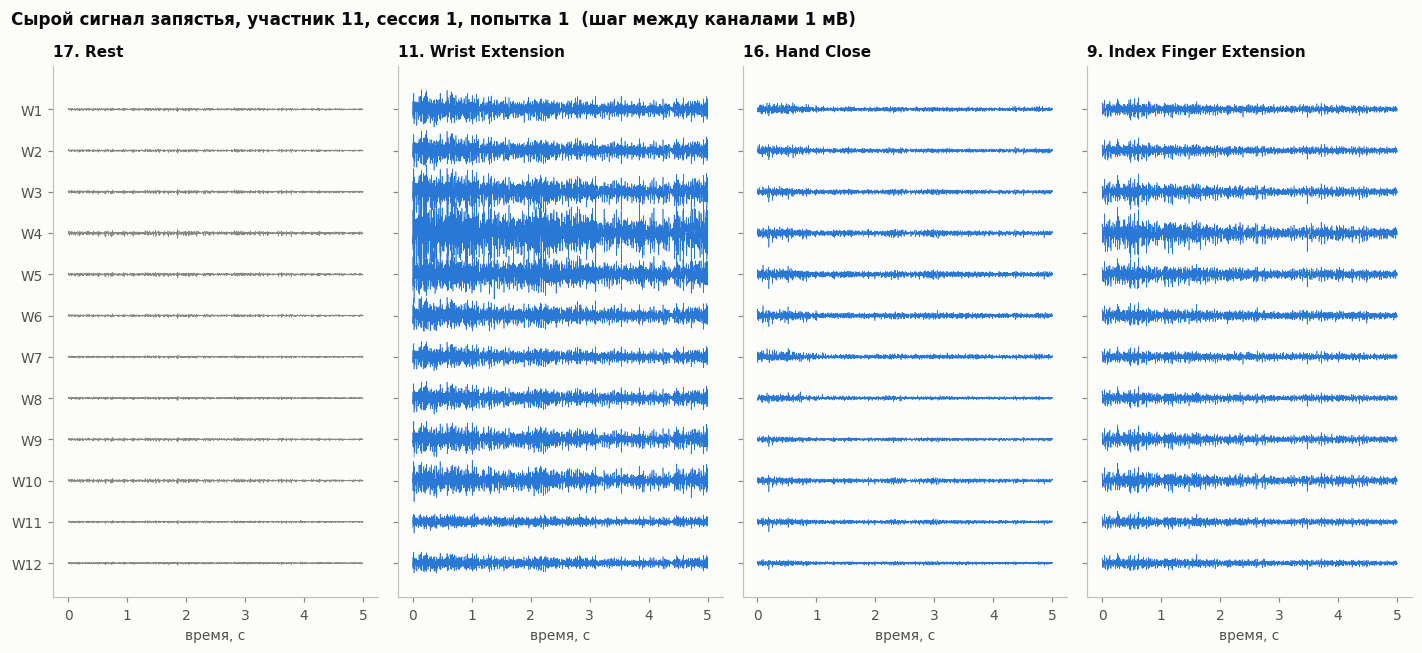

In [2]:
P, S, T = 11, 1, 1
SHOW = [17, 11, 16, 9]   # rest, wrist extension, hand close, index finger extension
t = np.arange(10240) / FS
OFFSET = 1.0             # mV between channel traces

fig, axes = plt.subplots(1, 4, figsize=(13, 6), sharey=True)
for ax, g in zip(axes, SHOW):
    x = load_trial(S, P, g, T)
    for c in range(12):
        ax.plot(t, x[:, c] - c * OFFSET, color=viz.REFERENCE if g == REST_GESTURE else viz.SERIES[0], lw=0.4)
    ax.set_title(f"{g}. {GESTURE_NAMES[g - 1]}")
    ax.set_xlabel("время, с")
    ax.grid(False)
axes[0].set_yticks(-np.arange(12) * OFFSET, [f"W{c + 1}" for c in range(12)])
fig.suptitle(f"Сырой сигнал запястья, участник {P}, сессия {S}, попытка {T}  (шаг между каналами 1 мВ)",
             x=0.01, ha="left", fontsize=11, fontweight="bold", color=viz.INK)
fig.tight_layout()
viz.save(fig, "01_raw_signals");

## 2. Огибающая: что происходит внутри попытки

Огибающая — RMS в скользящем **каузальном** окне 100 мс (каждая точка зависит только от прошлого):
$\mathrm{env}[n] = \sqrt{\tfrac{1}{W}\sum_{i=n-W+1}^{n} x_i^2}$.

Чтобы ответить, есть ли покой внутри попытки, смотрим не одну попытку, а все: 5 участников × 3 сессии × 7 попыток = 105 на жест.
Огибающая каждой попытки усреднена по каналам и поделена на её медиану, чтобы люди с разной амплитудой были сравнимы.

In [3]:
def envelope(x: np.ndarray, win_s: float = 0.1) -> np.ndarray:
    """Causal moving RMS over the last win_s seconds; first win-1 samples use a shorter window."""
    w = int(win_s * FS)
    c = np.cumsum(np.concatenate([np.zeros((1, x.shape[1])), x ** 2]), axis=0)
    n = np.arange(1, len(x) + 1)
    lo = np.maximum(n - w, 0)
    return np.sqrt((c[n] - c[lo]) / (n - lo)[:, None])

DEC = 32  # keep every 32nd sample (64 Hz) for plotting
env = {}  # gesture -> [n_trials, T/DEC] normalised mean-channel envelope
for g in range(1, 18):
    rows = []
    for _, r in idx[idx.gesture == g].iterrows():
        e = envelope(load_trial(r.session, r.participant, g, r.trial)).mean(axis=1)[::DEC]
        rows.append(e / np.median(e))
    env[g] = np.array(rows)
te = np.arange(env[1].shape[1]) * DEC / FS
keep = te >= 0.1  # first 100 ms: window not yet full, envelope is biased low
te = te[keep]
env = {g: e[:, keep] for g, e in env.items()}

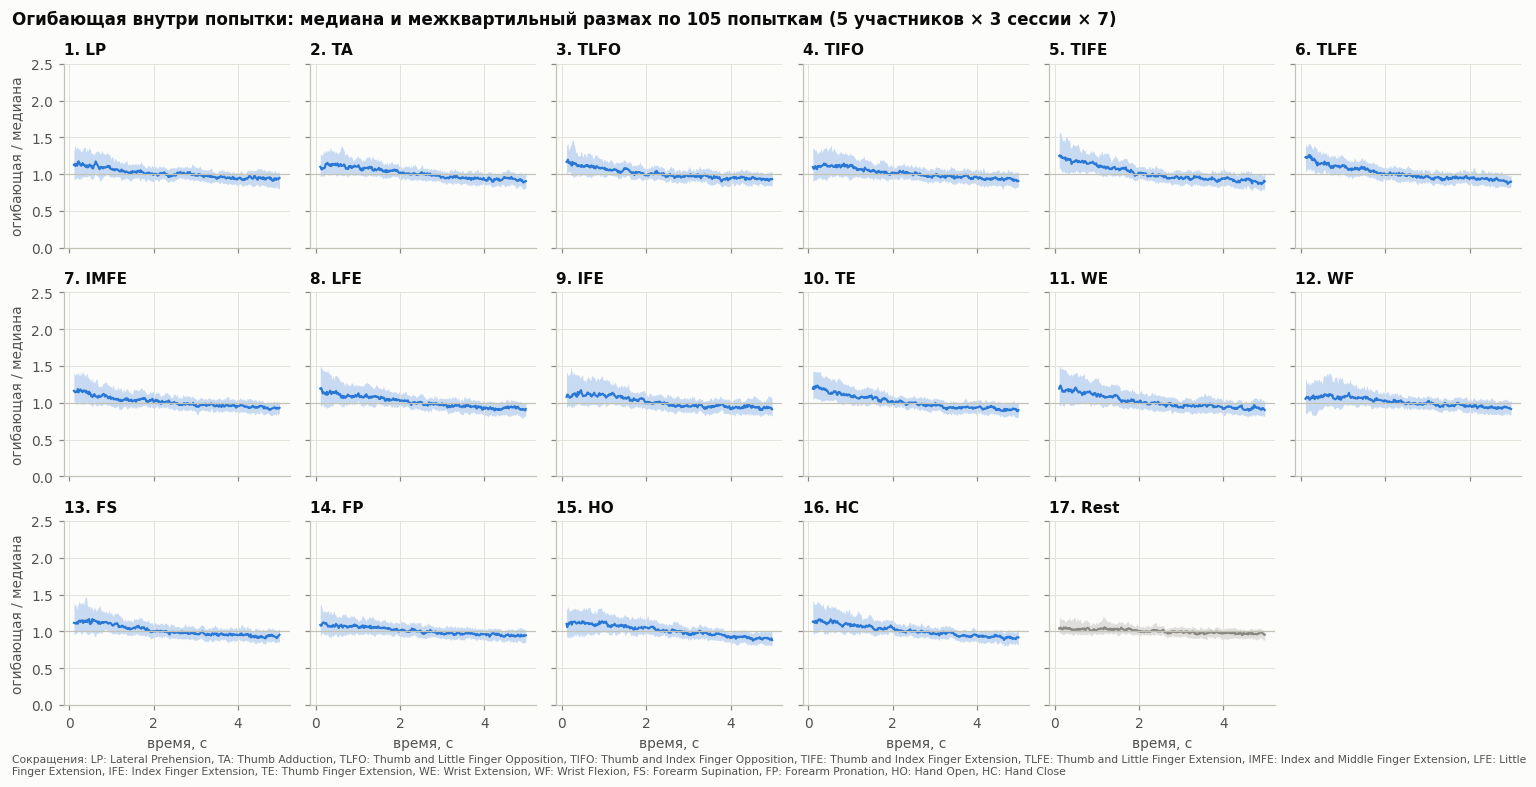

In [4]:
order = list(range(1, 17)) + [17]
fig, axes = plt.subplots(3, 6, figsize=(14, 7), sharex=True, sharey=True)
for ax, g in zip(axes.flat, order):
    q25, q50, q75 = np.percentile(env[g], [25, 50, 75], axis=0)
    color = viz.REFERENCE if g == REST_GESTURE else viz.SERIES[0]
    ax.fill_between(te, q25, q75, color=color, alpha=0.25, lw=0)
    ax.plot(te, q50, color=color, lw=1.4)
    ax.axhline(1, color=viz.AXIS, lw=0.8)
    ax.set_title(f"{g}. {GESTURE_SHORT[g - 1]}")
axes.flat[-1].axis("off")
for ax in axes[-1]:
    ax.set_xlabel("время, с")
for ax in axes[:, 0]:
    ax.set_ylabel("огибающая / медиана")
axes[0, 0].set_ylim(0, 2.5)
fig.text(0.01, -0.01, "Сокращения: " + ", ".join(f"{s}: {n}" for s, n in zip(GESTURE_SHORT[:16], GESTURE_NAMES[:16])),
         fontsize=7, color=viz.INK_2, wrap=True)
fig.suptitle("Огибающая внутри попытки: медиана и межквартильный размах по 105 попыткам (5 участников × 3 сессии × 7)",
             x=0.01, ha="left", fontsize=11, fontweight="bold", color=viz.INK)
fig.tight_layout()
viz.save(fig, "01_envelope_within_trial");

Количественно: доля попыток, в которых начало записи «тихое» — огибающая в 0,1–0,3 с меньше половины медианной.
Если жест начинается внутри записи, таких попыток должно быть много; если жест удерживается с начала — почти ноль.

In [5]:
early = (te >= 0.1) & (te < 0.3)
late = (te >= 4.7)
summary = pd.DataFrame({
    "gesture": [f"{g}. {GESTURE_NAMES[g - 1]}" for g in order],
    "quiet_start_%": [100 * np.mean(env[g][:, early].mean(1) < 0.5) for g in order],
    "quiet_end_%": [100 * np.mean(env[g][:, late].mean(1) < 0.5) for g in order],
    "early/median": [np.median(env[g][:, early].mean(1)) for g in order],
}).round(2)
summary

,gesture,quiet_start_%,quiet_end_%,early/median
0,1. Lateral Prehension,2.86,0.95,1.13
1,2. Thumb Adduction,3.81,0.00,1.10
2,3. Thumb and Little Finger Opposition,0.95,0.00,1.16
3,4. Thumb and Index Finger Opposition,3.81,0.00,1.12
4,5. Thumb and Index Finger Extension,3.81,0.00,1.22
5,6. Thumb and Little Finger Extension,3.81,0.00,1.24
6,7. Index and Middle Finger Extension,3.81,0.00,1.16
7,8. Little Finger Extension,3.81,0.00,1.13
8,9. Index Finger Extension,8.57,0.00,1.10
9,10. Thumb Finger Extension,2.86,0.00,1.23


## 3. Спектр: покой против жеста

Спектр Уэлча: окна по 2048 отсчётов (1 с, разрешение 1 Гц — достаточно, чтобы увидеть узкий сетевой пик), перекрытие 50 %,
окно Ханна. Спектр усреднён по 12 каналам и по всем попыткам класса внутри (участник, сессия 1).
Пунктир — 50 и 60 Гц с гармониками: данные записаны в Канаде, сеть там 60 Гц.

In [6]:
def mean_psd(rows: pd.DataFrame) -> tuple[np.ndarray, np.ndarray]:
    """Welch PSD (mV^2/Hz) averaged over channels and trials."""
    ps = []
    for _, r in rows.iterrows():
        f, p = signal.welch(load_trial(r.session, r.participant, r.gesture, r.trial), fs=FS,
                            nperseg=2048, noverlap=1024, axis=0)
        ps.append(p.mean(axis=1))
    return f, np.mean(ps, axis=0)

parts = sorted(idx.participant.unique())
psd = {}
for p in parts:
    for s in (1, 2, 3):
        sub = idx[(idx.participant == p) & (idx.session == s)]
        f, pr = mean_psd(sub[sub.gesture == REST_GESTURE])
        _, pg = mean_psd(sub[sub.gesture != REST_GESTURE])
        psd[p, s] = (pr, pg)

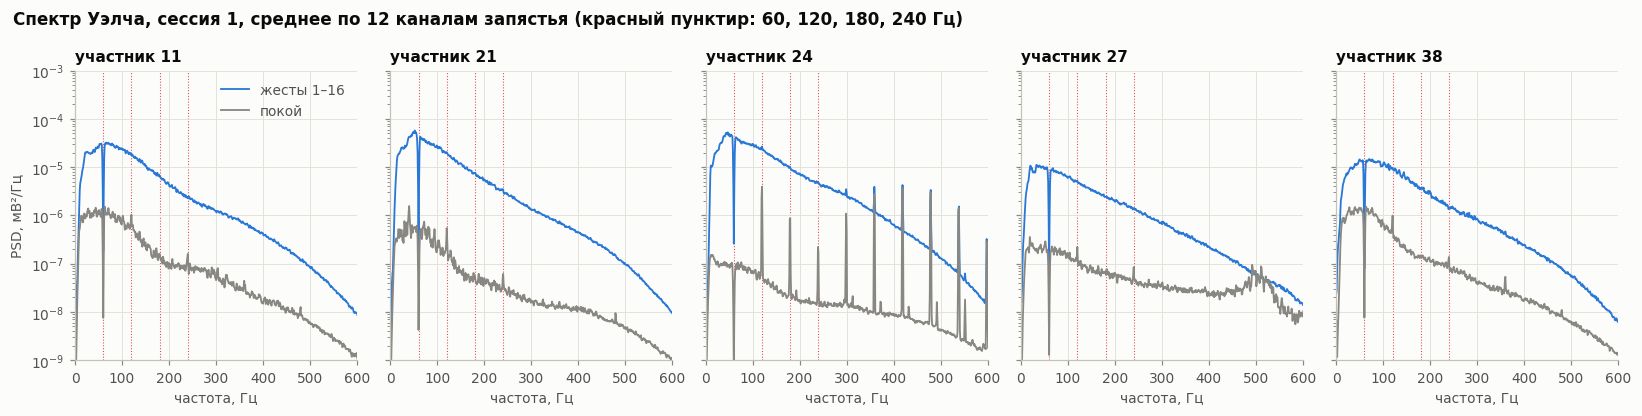

In [7]:
fig, axes = plt.subplots(1, len(parts), figsize=(15, 3.8), sharey=True)
for ax, p in zip(axes, parts):
    pr, pg = psd[p, 1]
    ax.semilogy(f, pg, color=viz.SERIES[0], lw=1.2, label="жесты 1–16")
    ax.semilogy(f, pr, color=viz.REFERENCE, lw=1.2, label="покой")
    for k in (1, 2, 3, 4):
        ax.axvline(60 * k, color=viz.SERIES[7], lw=0.7, ls=":", zorder=0)
    ax.set_xlim(0, 600)
    ax.set_ylim(1e-9, 1e-3)
    ax.set_title(f"участник {p}")
    ax.set_xlabel("частота, Гц")
axes[0].set_ylabel("PSD, мВ²/Гц")
axes[0].legend(loc="upper right")
fig.suptitle("Спектр Уэлча, сессия 1, среднее по 12 каналам запястья (красный пунктир: 60, 120, 180, 240 Гц)",
             x=0.01, ha="left", fontsize=11, fontweight="bold", color=viz.INK)
fig.tight_layout()
viz.save(fig, "01_welch_rest_vs_gesture");

Увеличение вокруг 60 Гц с разрешением 0,25 Гц (окно 8192 отсчёта = 4 с): форма провала покажет, что именно сделали с записью.

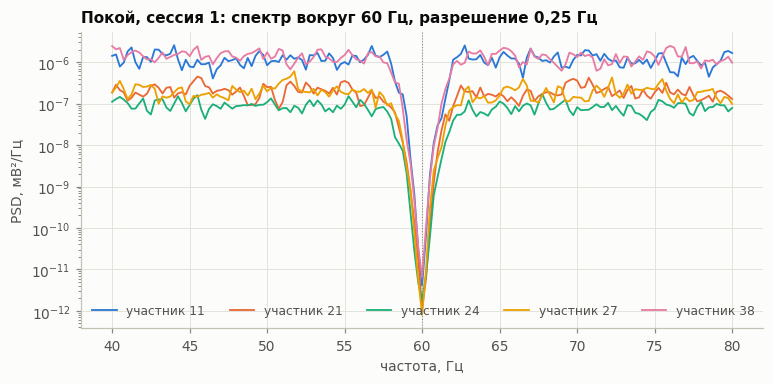

In [8]:
fig, ax = plt.subplots(figsize=(8, 3.5))
for i, p in enumerate(parts):
    rows = idx[(idx.participant == p) & (idx.session == 1) & (idx.gesture == REST_GESTURE)]
    ps = [signal.welch(load_trial(r.session, r.participant, r.gesture, r.trial), fs=FS, nperseg=8192, axis=0)[1].mean(1)
          for _, r in rows.iterrows()]
    fz, pz = signal.welch(np.zeros(8192), fs=FS, nperseg=8192)[0], np.mean(ps, axis=0)
    sel = (fz >= 40) & (fz <= 80)
    ax.semilogy(fz[sel], pz[sel], color=viz.SERIES[i], lw=1.2, label=f"участник {p}")
ax.axvline(60, color=viz.MUTED, lw=0.7, ls=":")
ax.set_xlabel("частота, Гц"); ax.set_ylabel("PSD, мВ²/Гц")
ax.legend(ncol=5, loc="lower left", fontsize=8)
ax.set_title("Покой, сессия 1: спектр вокруг 60 Гц, разрешение 0,25 Гц")
viz.save(fig, "01_notch_60hz_zoom");

Сетевой пик количественно: мощность в полосе ±1 Гц вокруг частоты против медианы соседних полос (±3–8 Гц), в дБ.
0 дБ — пика нет; 10 дБ — пик в 10 раз выше окружающего спектра. Плюс отношение мощности жестов к покою в полосе 20–450 Гц.

In [9]:
def peak_db(p: np.ndarray, f0: float) -> float:
    on = np.abs(f - f0) <= 1
    off = (np.abs(f - f0) >= 3) & (np.abs(f - f0) <= 8)
    return 10 * np.log10(p[on].mean() / np.median(p[off]))

band = (f >= 20) & (f <= 450)
rows = []
for (p, s), (pr, pg) in psd.items():
    rows.append({"participant": p, "session": s,
                 "rest 50Hz dB": peak_db(pr, 50), "rest 60Hz dB": peak_db(pr, 60),
                 "rest 120Hz dB": peak_db(pr, 120), "rest 180Hz dB": peak_db(pr, 180),
                 "gesture/rest power 20-450": pg[band].sum() / pr[band].sum(),
                 "rest power <20Hz, %": 100 * pr[f < 20].sum() / pr.sum()})
noise = pd.DataFrame(rows).round(1)
noise

,participant,session,rest 50Hz dB,rest 60Hz dB,rest 120Hz dB,rest 180Hz dB,gesture/rest power 20-450,"rest power <20Hz, %"
0,11,1,0.2,-11.2,2.0,0.8,27.6,6.9
1,11,2,0.2,-11.9,1.6,0.4,79.8,5.3
2,11,3,-0.0,-10.9,5.0,0.4,15.5,3.6
3,21,1,0.5,-11.6,3.8,0.3,84.7,7.2
4,21,2,0.1,-11.0,0.9,0.4,30.5,5.5
5,21,3,0.1,-10.9,2.6,-0.3,29.8,5.0
6,24,1,-0.2,-12.1,16.7,14.5,147.4,3.9
7,24,2,-0.2,-11.4,9.6,1.4,219.7,19.2
8,24,3,0.2,-11.5,8.6,1.4,92.1,4.5
9,27,1,0.9,-11.6,1.6,-0.1,37.6,6.1


## 4. Спектрограмма одной попытки

Как спектр меняется во времени. Окно 256 отсчётов (125 мс), шаг 32 (16 мс). Канал W4.
Цвет — PSD в дБ относительно 1 мВ²/Гц: $10\log_{10}(S / 1\,\text{мВ}^2/\text{Гц})$, т. е. −40 дБ = 10⁻⁴ мВ²/Гц (сверяется со спектром Уэлча).
Одна шкала на обе панели; диапазон цвета — 60 дБ вниз от общего максимума.

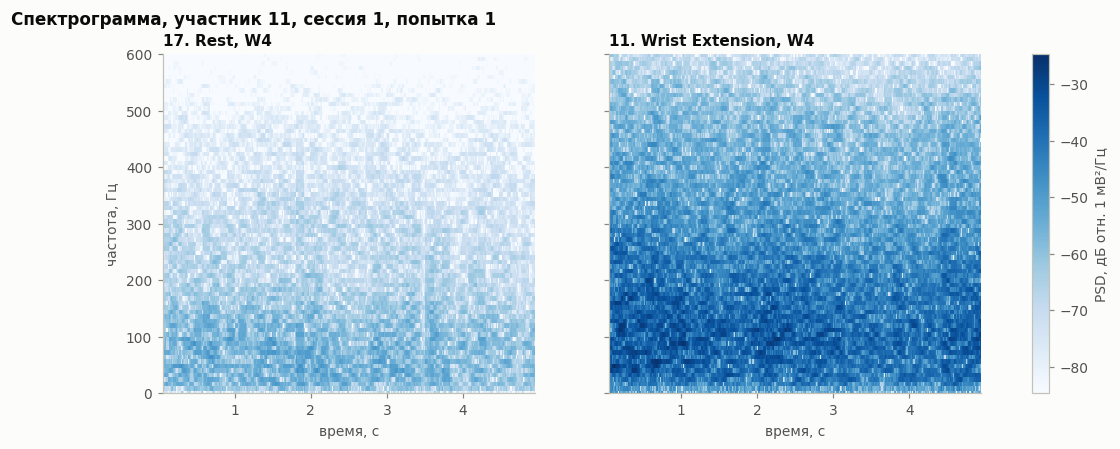

In [11]:
CH = 3  # W4
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
specs = {}
for g in (REST_GESTURE, 11):
    fs_, ts_, Sxx = signal.spectrogram(load_trial(S, P, g, T)[:, CH], fs=FS, nperseg=256, noverlap=224)
    specs[g] = (fs_, ts_, 10 * np.log10(Sxx + 1e-20))  # dB re 1 mV^2/Hz
vmax = max(v[2].max() for v in specs.values())
for ax, g in zip(axes, (REST_GESTURE, 11)):
    fs_, ts_, db = specs[g]
    im = ax.pcolormesh(ts_, fs_, db, vmin=vmax - 60, vmax=vmax, cmap="Blues", shading="auto")
    ax.set_ylim(0, 600)
    ax.set_title(f"{g}. {GESTURE_NAMES[g - 1]}, W4")
    ax.set_xlabel("время, с")
    ax.grid(False)
axes[0].set_ylabel("частота, Гц")
fig.colorbar(im, ax=axes, label="PSD, дБ отн. 1 мВ²/Гц")
fig.suptitle(f"Спектрограмма, участник {P}, сессия {S}, попытка {T}", x=0.01, ha="left",
             fontsize=11, fontweight="bold", color=viz.INK)
viz.save(fig, "01_spectrogram");

## Выводы

1. **Внутри попытки нет покоя.** Жест удерживается все 5 с: огибающая с 0,1 с на уровне ≈1,1 медианы и плавно спадает к ≈0,9 к концу.
   Попыток с «тихим» началом 1–12 % на жест — столько же, сколько шумовых колебаний. Запись — это фрагмент удерживаемого сокращения, а не «покой → жест → покой».
2. **В данных уже есть режекторный фильтр на 60 Гц** (в документации не указан): провал ≈ −12 дБ в полосе ±1 Гц, глубиной до 10⁻¹² мВ²/Гц, шириной ≈ 4 Гц, у всех участников и сессий, и в покое, и в жестах.
   Гармоники 120, 180, … Гц не вырезаны: у участника 24 в сессии 1 пики до +17 дБ на 120 Гц и вплоть до 540 Гц — видны даже поверх спектра жестов.
3. **Форма спектра EMG** — максимум около 40–80 Гц, спад примерно на 3–4 порядка к 600 Гц. Ниже ~10 Гц мощность обрезана аппаратным фильтром; в покое на < 20 Гц приходится 3–7 % мощности (выброс: 24/сессия 2 — 19 %).
4. **Отношение мощности жест/покой (20–450 Гц) — от 7 до 220 раз** и сильно меняется между сессиями одного участника (участник 27: 38 → 12 → 7). Это материал этапа 2.
